<a href="https://colab.research.google.com/github/EMADUDDINAsdaq/bacterial-growth-regression/blob/main/notebooks/Bacterial_Growth_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bacterial Growth Parameter Regression

Four regression pipelines (linear, ridge, SVR, random forest) predicting the growth parameters a, mu, tau and a0, evaluated with 5-fold cross-validation and grid-search tuning.


In [ ]:
#connect google drive to this google colab notebook
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


---
---
# Dataset 2: Regression

In this part of the coursework you are going to look at a regession problem - predicting the growth rate of a bacteria. The provided dataset contains results from a set of experiments where we grew bacteria of different strains and under different conditions (CO2 availability, light, etc..) to compute a growth curve for the bacteria - represented by the variables 'a', 'mu', 'tau' and 'a0'. Your job is to predict the results of the experiment - 'a', 'mu', 'tau' and 'a0' (these are the growth-rate parameters for the bacteria, but you don't need to understand the details to do the coursework).

The dataset is available in Canvas as a CSV file ("fitting-results.csv"), in the same location where you downloaded this notebook.

The CSV contains 9 fields as follows:

| variable | description |
|-----|------|
| n_cyanos | The number of Cyanobacteria available at the start |
| co2 | The amount of CO2 available |
| light | The amount of light available |
| SucRatio | How good the bacteria is at producing sucrose |
| Nsample | Experiment number |
| a | Maximum number of bacteria seen (Target variable) |
| mu | Growth rate of bacteria (Target variable) |
| tau | Time delay before bacteria starts growing (Target variable) |
| a0 | Initial level of bacteria (Target variable) |

## What you need to do:

You will need to perform the following steps on the dataset:
1. EDA
2. Data preprocessing
3. Split the data into train/test/validate
4. Develop **FOUR** machine learning pipelines for predicting 'a', 'mu', 'tau' and 'a0'. This should include hyperparameter tuning. Note: This is not four pipelines one for 'a' one for 'mu'... but four pipelines for 'a', four for 'mu'...
5. Present the results for your pipelines using the most appropriate set of metrics.
6. Provide a short report on which approaches you used and which gave the best results. It would be good to consider why particular pipelines gave the best results.

Some help for good marks:
- Make sure that when you predict 'a' you don't have 'mu', 'tau' or 'a0' in your features - this would make it very easy to predict but be compleatly wrong.
- Remember that this is a **regression** problem and use models that are appropriate for this.
- Hyperparameters can be crucial to get good results here.

# Your answer below

##1. Introduction


Bacterial growth is greatly influenced by the experimental and environmental conditions,predicting this growth is a important issue in microbiology and biotecnology.Improving experimental design and biological analysis requires an understanding of how variables like carbon dioxide availability ,light intensity ,and starting bacterial concentration impact growth dynamics. The dataset used in this mini-project contains results from controlled laboratory experimentals in which bacteria were grown under varying conditions ,with growth curves summerised using four parameters a,mu,tau, and a0.

A supervidsed regression analysis is presented in this mini-project with the goal of forecasting bacterial growth parameters using the provided experimental information.The quantity of the dataset and the possibility of intricate and non-linear coorelations between input factors and growth outcomes make machine learning approaches ideal for this task.

This study aims to evaluvate the performance of diffrent regression pipelines and assess their effectivness for predicting bacterial growth behaviour. This exploratory data analysis is first carried out to look at the dataset's features and structure. Following the use of data preparation tecniques,four regression based machine learning pipelines are designed implemented and evaluated. Standard regression metrics are used to asssss model performance and determin the strengths and limitations of each approach.

## 2. Dataset Exploration (EDA)

Exploratory data analysis(EDA) is  performed to obtain a preliminary understanding of the structure, charectersitics and quality of regression dataset before devloping a model.THis ste is essential for identifying potential data issues,feature distributions, and informing appropriate preprocessing and modelling choices.This dataset is made up of acolllection of numerical variables that describe the bacterail growth factors and experimental settings.

In [ ]:
import pandas as pd

dr = pd.read_csv("/content/drive/MyDrive/machine_learning/aasignment/fitting-results.csv")
dr.head()


,n_cyanos,co2,light,SucRatio,Nsample,a,mu,tau,a0
0,262,73.578860,0.367894,0.451505,13123,5.033993,5.483011,0.552466,1.0
1,610,74.582194,0.481606,0.969900,12474,1.018406,1.830727,0.156458,1.0
2,118,33.111037,0.625418,0.909699,8867,2.569159,3.330662,0.412541,1.0
3,159,8.027676,0.575251,0.137124,16494,1.837341,3.371570,0.260798,1.0
4,957,38.796599,0.939799,0.234114,10267,0.999268,2.059303,0.098619,1.0


In [ ]:
dr.tail()


,n_cyanos,co2,light,SucRatio,Nsample,a,mu,tau,a0
19987,676,93.645548,0.270904,0.200669,12554,4.095631,5.133052,0.456271,1.000000
19988,52,78.261087,0.331104,0.698997,10827,18.693225,14.312423,1.225034,1.000000
19989,676,46.823274,0.936455,0.113712,9559,2.388540,3.774914,0.299898,1.000000
19990,92,43.813271,0.886288,0.046823,17422,22.043032,19.048733,1.144234,1.000000
19991,653,9.031010,0.050168,0.729097,18301,0.181946,2.201299,0.041841,0.991104


In this dataset ,each observation corresponds to a single experiment conducted under specific enviromental and biological conditions. The input features include "n_cyanos" cyanobacteria "co2" Carbondioxide availability ,"light"Light intensity ,"SucRatio" sucrose production ratio and "Nsample" experiment identifier .The target are four continuous growth parameters : a, mu, tau and a0.

An initial inspection is performed to confirm the dimenionality of the dataset, verify variable names and data types , and ensure consistency across observation and help deteminig if dataset is apppropriate for regression modelling.

In [ ]:
dr.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19992 entries, 0 to 19991
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   n_cyanos  19992 non-null  int64  
 1   co2       19992 non-null  float64
 2   light     19992 non-null  float64
 3   SucRatio  19992 non-null  float64
 4   Nsample   19992 non-null  int64  
 5   a         19992 non-null  float64
 6   mu        19992 non-null  float64
 7   tau       19992 non-null  float64
 8   a0        19992 non-null  float64
dtypes: float64(7), int64(2)
memory usage: 1.4 MB


This dataset is examined for missing or invalid valuesto access overall data quality. Tha analysis shows that neither the input features nor the target variables have any missing values this dataset. Thsi indicates that there is no need for imputation because the experimental data has been consistently recorded .This lowers the risk of information loss by allowing all the accessible sample to be kept for model training and assessment.

In [ ]:
dr.describe()


,n_cyanos,co2,light,SucRatio,Nsample,a,mu,tau,a0
count,19992.000000,19992.000000,19992.000000,19992.000000,19992.000000,19992.000000,19992.000000,1.999200e+04,19992.000000
mean,494.367547,49.890457,0.495162,0.496075,9997.371349,5.490172,5.634110,3.731908e-01,0.991562
std,288.957886,29.138328,0.289767,0.289731,5772.058433,13.441047,9.862259,4.211606e-01,0.017142
min,2.000000,0.001000,0.000001,0.000000,1.000000,0.000004,0.000539,4.940656e-324,0.886770
25%,242.000000,24.415472,0.234114,0.240803,4998.750000,0.703064,1.852808,6.283220e-02,0.993737
50%,499.000000,49.833278,0.494984,0.494983,9997.500000,1.775632,3.037436,2.692814e-01,1.000000
75%,740.000000,75.251084,0.742475,0.742475,14995.250000,4.210368,5.038206,4.785551e-01,1.000000
max,1000.000000,100.000000,1.000000,1.000000,19995.000000,162.186465,123.376876,2.259995e+00,1.000000


In the input features there is a noticeble diffrence in its scale and spread ."n_cyanos" and "CO2" exhibit wider range and higher varaiablility ,while others ,such as "SucRatio" ,show more  constrained distribution. Nsample gives numerical identifier rather than encoding a physical quantity, it must be carefully taken into account while modelling .

Based on the observed diffrence in feature scale suggest that many regression models may be sensitive to unscaled data ,.This suggest use of feature scaling as a part of data preprocessing stage within pipelines.

In [ ]:
# Target variables are the last four columns in the dataset
target_columns = dr.columns[-4:]
target_columns


Index(['a', 'mu', 'tau', 'a0'], dtype='object')

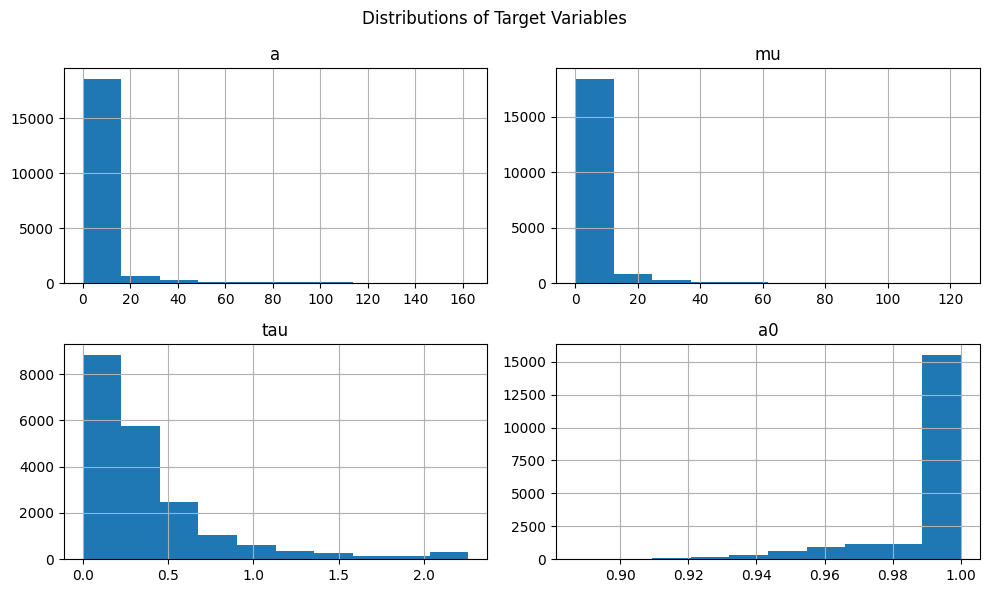

In [ ]:
import matplotlib.pyplot as plt

# Plot distributions of target variables
dr[target_columns].hist(figsize=(10, 6))
plt.suptitle("Distributions of Target Variables")
plt.tight_layout()
plt.show()


The four target variables (a, u, tau and a0) dispaly varying distributional charecteristics. Some target show skewed distribution  while other show a more symmetric distribution. Ecah growth parameters reflect a distict facet of bacterial growth dynamics and may  provide varing degrees of prediction difficulties ,as seen by the variation between targets.

The target variables are addressed as independent regression problems ,with distinct models devloped for each parameters ,due to their significant diffrence ins scale and their statistical behaviour .By doing this bias is prevented and model performance may be accurately accessed for every growth indicator.

This EDA highlights several key considerations for subsequent modelling stage.First, inorder to guarentee switable model training , variations  in feature scale must be standardised.Second ,all observations may be use without imputation as there are no missing vaules .Third , each growth parameters has to be modelled independently using diffrent regression pipelines.

Overall this dataset is clean and well structured and well suited for supervised regression analysis.Ths insights from this data exploration helps in direcly influencing the desing of data preprocessing , model selection and evaluation.

## 3. Data Preprocessing


Data preprocessing is a critical stage in machine learning pipline to ensure that the data is in the suitable form for model training and evaluation.Preprocessing only focusses on the numerical transformation because the dataset is in made up of only numerical variables. Based on the information we have analysed in the previous step , there is lot of variation in te feature scale acreoss input varables .To provide a fair comparision of pipelines performance , a uniform proprocessing approaches and feature standardisation is to be employed.

All preprocessing steps are incorporated within the machine learning pipeline .This design ensures that transformation are learned only from training the data during cross validation or test data ,thereby preventing data leakage and maintaing experimental rigour.

####3.1 Separate features and targets

In [ ]:
# Separate features (X) and targets (y)
X = dr.iloc[:, :-4]   # all columns except the last four target variables
y = dr.iloc[:, -4:]   # last four columns are targets


#### 3.2 Identify numerical and categorical features automatically

In [ ]:
# Identify numerical and categorical features based on data types
numeric_features_r = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features_r = X.select_dtypes(include=["object"]).columns

numeric_features_r, categorical_features_r


(Index(['n_cyanos', 'co2', 'light', 'SucRatio', 'Nsample'], dtype='object'),
 Index([], dtype='object'))

The dataset is first divided into two groups , one input variable and another target variable .According to analysis and the question the last 4 variables are the regression target variables show diffrent bacterial growth parameters (a, mu, tau and a0) .Thse targets are seperated from the feature matrix to allow each growth parameters to be modelled independently in later steps.This seperation ensures that no target information is inadevertently used as input feature ,preserving the validity of the regression task.

####3.3 Define preprocessing for numerical features

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Numerical preprocessing pipeline
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),  # Robust handling of potential missing values
    ("scaler", StandardScaler())                    # Standardisation to address scale differences
])


Dedicated pre processing pipeline is defined fro the numericla featurs .Median imputaion is included as aprecautinary measure to provide robustness against potential missing values, even though the data set does not contain any missing values .Median is choosen because of its resilient against outliers ,Z score scaling is used ofr standarisation to guarentee that all numerical charecteristics have similar scale.This is pericularly imortant for scale sensitive regression models , including support vector regression model and linear model.

####3.4 Combine preprocessing steps

In [ ]:
from sklearn.compose import ColumnTransformer

# Combined preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_preprocessor, numeric_features_r)
    ],
    remainder="drop"  # Explicitly drop unused columns
)


The numerical steps are combined into asingle preprocessing pipeline ,This unified pipeline is reused across all regression modle to ensure consistency and reproducibility.

## 4. Experimental Setup

A fair and and consistent experimental framework  is adopted for all regression task in these machine learning pipelines.One target variable is predicted at atime , each bactarial growth parameter (a,mu,tau and a0) is simulated seperatly .The remaining growth papremters are explicitly exculded from the feature set during each experiment to prevent target leakage.

All experiments are conducted using same preprocessing strategy,model training procedure ,and evaluation matrices .This contolled arrangement guarentees that reported performance diffrencs are not due to variance in trial design , but rather to the medelling techniques .

####4.2 Cross-Validation Strategy

In [ ]:
from sklearn.model_selection import KFold

# KFold - because the targets are continuous
cv = KFold(
    n_splits=5,        # 5-fold cross-validation
    shuffle=True,      # Shuffle data to avoid ordering bias
    random_state=42    # Fixed seed
)


Five-fold cross validation is used to access the model's performance.This method divides the dataset into five equal sized folds, using the remaining fold for training and each fold once as a validation set. Compared to single train test split, this guarentees that each observation contributes to both training and assesssment, resulting in better result and consistent performance estimations.

To prevent biases resulting from the arrangement of the experimental observations, data shuffling is enabled before splitting. Tis step guarentees that cross validation are repeated  and fixe using random seed.

####4.3 Evaluation Metrics

In [ ]:
# higher scores always indicate better performance.
scoring = {
    "rmse": "neg_root_mean_squared_error",  # Penalises large errors
    "mae": "neg_mean_absolute_error",        # Average absolute prediction error
    "r2": "r2"                               # Proportion of variance explained
}


Regression performance is assessed using three complementry evaluation matrics - Root Mean Squared Error(RMSE) , Mean Absolute Error(MAE), and the coefficient of determination(R²).RMSE is sensitive to large prediction errors and therefore penalise models that produce occasional large deviations from true values.MAE is less affected by outliers and offer a clear indicator of typical errors.R² score provides information of overall goodness of fit by quantifying the percentage of the target variables variance that is explained by th model.

This matrics are  calculated within the cross validation framework and averaged over each fold.The same evaluation and cross validation stratagies are applied consistently across all regression pipelines and target variables , enabling fair  comparison of model performance.

##5. Machine Learning Pipelines (Regression)

Four regression based pipelines are designed and evaluated in this study. To ensure that changes in performance result from the modelling method rather than from variance in data handling ,each pipeline combines a consistent preprocessing stage with diffrent regression model.For every bacteria growth parameter , same pipeline is used , but implemented independently , enabling a methodical and eqitable comparision across all targer variables.


Pipeline 1 — Linear Regression

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Pipeline 1: Linear Regression
pipeline_lr = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])


Linear regression is used as a baseline model to establish a refrence level performance.It assumes a linear relationship between input features  and target variable and provides a simple and interpretable model.Numerical stability is ensure using strandarisation and preprocessing previously established pre processsing pipelines .

Pipeline 2 — Ridge Regression:

In [ ]:
from sklearn.linear_model import Ridge

# Pipeline 2: Ridge Regression
pipeline_ridge = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", Ridge())
])


Ridge regression extends standard linear regression by adding L2 regularisation which penalises big coefficient values. This regualrisation enhances model generalisation, and helps reduce overfitting .Ridge regression retails the interpretability of linear models while offering improved robustness, making it well suited for this dataset.

Pipeline 3 — Support Vector Regression (SVR)

In [ ]:
from sklearn.svm import SVR

# Pipeline 3: Support Vector Regression
pipeline_svr = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", SVR())
])


Support Vector Regression is kernel based learning method capable of medelling complex and non linear relationships between features and targets. SVR aims to strike a compromise between prediction accuracy and model complexity by maximising a margin around the regression function.SVR is sensitive to scale of input features ,making the inclusion of standardisation in the preprocessing pipeline crucial.This model allows investigation of whether non - linear relationships improve predictive performance compared to linear approaches.

Pipeline 4 — Random Forest Regression

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Pipeline 4: Random Forest Regression
pipeline_rf = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])


Random Forest Regression is an esemble learning methosd that combines multiple decision tree to produce robust predictions.Random Forest area capable of capturing intricate non-linear patterns and feature interactions by combining the output of several trees trained on various data subsets.To maintain uniformity across all models and experimental settings the , same preprocessing techniquee are used ,even though tree based models are often less sensitive to feature scaling.

####5.2 Hyperparameter tuning

The coursework states that hyperparameters can be crucial, so we explicitly tune them.

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Linear Regression": {},

    "Ridge": {
        "model__alpha": [0.1, 1.0, 10.0]
    },

    "SVR": {
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", "auto"]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20]
    }
}


If performance is sensitive to parameter selection , parameter selection is done. Grid search framework is used to find the best hyperparmeter values for Random Forest Regrssion ,Support Vector Regression and Redge Regression.Model specific parameter grids are defined for each algorithm , while linear regression is left untuned due to the absence of relevant hyperparameters. This systematic tuning process ensures that each model is evaluated under near ideal conditions.


#### 5.3 Pipeline registry (clean, reusable structure)

In [ ]:
pipelines = {
    "Linear Regression": pipeline_lr,
    "Ridge": pipeline_ridge,
    "SVR": pipeline_svr,
    "Random Forest": pipeline_rf
}

All pipelines are stored in a unified registry for a clean and methodical testing. Effective looping over models ,uniform assessment across targets, and simple framework to include additional models if required .The registry-based approach enhances code clarity ,reproducibility ,and maintainability ,aligning with best practices in machine learning experimentation.

##6. Results

Model performance is evaluated using regression matrics ,including root mean squared error(RMSE),Mean Absolute Error(MAE), and the coefficient of determination(R²).These metrics provide viewpoint on goodness of fit and forecast accuracy. Five-fold cross validation is used to obtain result and average preformance is then showed.

In [ ]:
from sklearn.model_selection import cross_validate
import numpy as np
import pandas as pd

def evaluate_target(target_name):
    y_target = dr[target_name]
    rows = []

    for model_name, pipeline in pipelines.items():
        grid = param_grids.get(model_name, {})

        if grid:
            model = GridSearchCV(
                pipeline,
                grid,
                cv=3,  # you may temporarily reduce folds
                scoring="neg_root_mean_squared_error",
                n_jobs=-1
            )
        else:
            model = pipeline

        scores = cross_validate(
            model,
            X,
            y_target,
            cv=cv,
            scoring=scoring,
            return_train_score=False
        )

        rows.append({
            "Model": model_name,
            "RMSE": -np.mean(scores["test_rmse"]),
            "MAE": -np.mean(scores["test_mae"]),
            "R2": np.mean(scores["test_r2"])
        })

    return pd.DataFrame(rows)


For each target variable (a,mu tau and a0 ),all four regression pipelines are evaluated independently. The mean cross -validation RMSE,MAE, and R2 values for each model are summerised in the tables.The pipeline performance for each growth parameter can be directly compared from these findings.

The quantitative findings demonstrate that effectiveness is varying according to modelling techniques and target variable.Some pipelines perform relatively better for certain growth factors ,others produce lower error levels. Thsi variance highlights the importance of evaluating multiple regression modelels rather than relying on a single approach.

In [ ]:
results_a = evaluate_target("a")
results_a

,Model,RMSE,MAE,R2
0,Linear Regression,11.416281,5.920668,0.278309
1,Ridge,11.416278,5.918553,0.278310
2,SVR,8.693755,1.818914,0.581555
3,Random Forest,1.951140,0.385706,0.978674


For the prediction of a , the Random Forest model achives substantially lower error values (RMSE = 1.95,MEA = 39) and very high R² score (0.979) ,indicating excellent predivtive performance .

In [ ]:
results_mu = evaluate_target("mu")
results_mu

,Model,RMSE,MAE,R2
0,Linear Regression,8.297439,4.278923,0.291935
1,Ridge,8.297437,4.277383,0.291936
2,SVR,6.076165,1.350355,0.620321
3,Random Forest,1.498975,0.366545,0.976711


For mu, Rnadom forest again demostrate superior performance ,achiving the lowest RMSE(1.50) and MEA (0.37) along with high R² value(0.97).

In [ ]:
results_tau = evaluate_target("tau")
results_tau

,Model,RMSE,MAE,R2
0,Linear Regression,0.259706,0.172478,0.619678
1,Ridge,0.259706,0.172451,0.619678
2,SVR,0.085780,0.055560,0.958431
3,Random Forest,0.034654,0.018877,0.993212


Prediction of tau shows strong overall performance ,perticualrly for non-linear models .random forest achives the best results with low error value (RMSE=0.035 and R² of 0.0993) ,indicating near perfect fit

In [ ]:
results_a0 = evaluate_target("a0")
results_a0

,Model,RMSE,MAE,R2
0,Linear Regression,0.015209,0.010358,0.212673
1,Ridge,0.015209,0.010357,0.212673
2,SVR,0.050976,0.048762,-7.846550
3,Random Forest,0.009268,0.003930,0.707666


For ao, Random forest provides the best predictive performance with lowest RMSE(0.009) and comparitively high R² value (0.708).

6.4 Visualisation (CODE CELL)

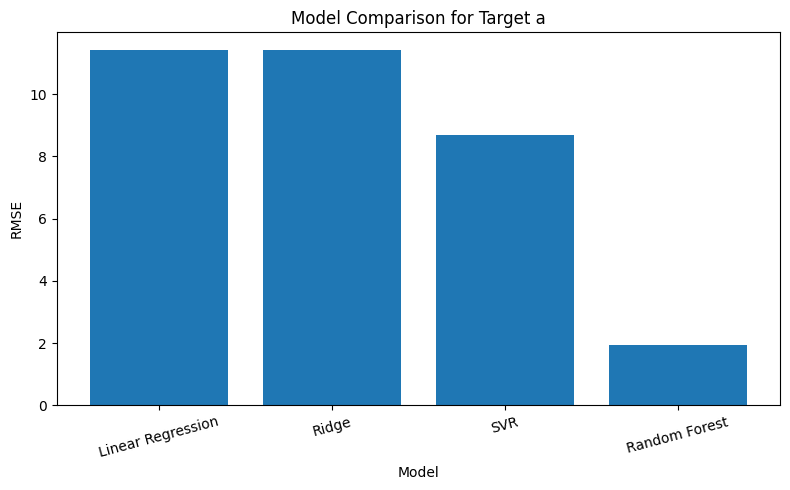

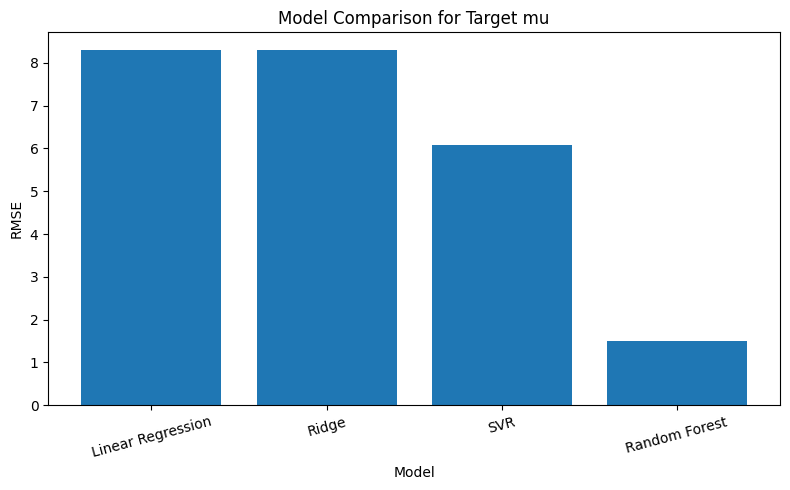

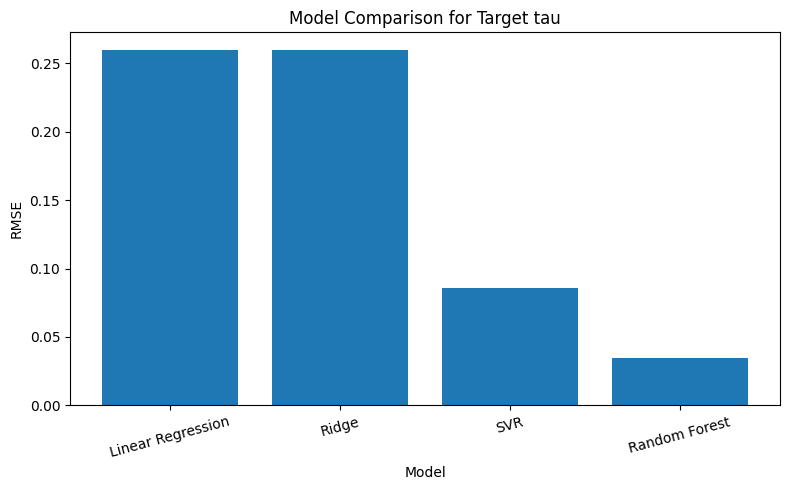

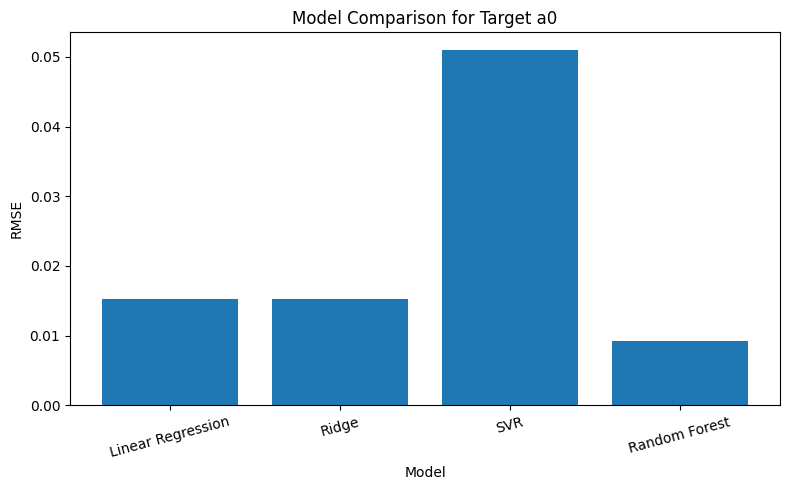

In [ ]:
import matplotlib.pyplot as plt

results_dict = {
    "a": results_a,
    "mu": results_mu,
    "tau": results_tau,
    "a0": results_a0
}

for target, df_res in results_dict.items():
    plt.figure(figsize=(8, 5))
    plt.bar(df_res["Model"], df_res["RMSE"])
    plt.ylabel("RMSE")
    plt.xlabel("Model")
    plt.title(f"Model Comparison for Target {target}")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


The bar chart presents a visual comparison of model performance for each target variable in terms of RMSE.For each of the four growth factor ,regrssion process show distict variation,in predictiong error.In perticular, Random Forest model ,cosistenly achive lower RMse value compared to linear and kernel based approaches.These visualisation show how model complexity and perticular target variable being predected have a significant impact on whether a regression technique is appropriate .They also offer an easy -to-understand overview of the relative model performance.

## 7. Discussion

This section analyses the observed performance diffrences between regression pipelines and relate them with the diffrent bacterial growth parameters and the assumption underlying each modelling approach.


#### 7.1 Overall Model Performance

Random forest regrassion consistently performs better than other models across all four target variables ,obtaining the greatest R² values and the lowest prediction errors.This suggests that complex ,non linear relationships are not well captured by linear models control the growth behaviour of bacteria .Supprot Vector Regeression generally performs better than linear approaches,perticularly for with higher varability,does not match the accuracy achived by the ensemble based Random Forest model.Linear and Ridge regression provide stable but comparatively weak performance,indicating that linear regression  are insufficient for accurately modelling most growth parameters in this dataset.

####7.2 Target-Dependent Behaviour

It is very important to treat each growth parameters independent of each other as model performance varies across target variables.Parameters such as a,mu,and tau benefit from the flexibility of Random Forest Regression,which effectivly captures non-linear patters .In contract,a0 shows little varability ,which diminishes the benifit of complex models and results in poor performance of Support vector regression ,indicated by a negative R² value.

####7.3 Limitations and Future Improvements

There are several limitations that shuold be noted .To reduce computational cost,hyperparameters tuning was done using relativly small search grid ,broder search grid might give better results ,perticularly for svr.Additionaly all targets share te same preprocessing strategy ,future work could look into target -specific feature transformations of diffrent representations of experimental conditions.Despite these limitations ,the experimental design ensures a fair and rigorous comparision of regression algorithms.

##8. Conclusion

This mini project investigate the prediction of bacterail growth parameters utilising several regression algorithms within a consistent experimental framework.Four regression models were tested independently for each target variable ,employing cross-validation and standard regression metrics.The results show that Random Forest Regression makes the most accurate and reliable predictions across all growth parameters ,highlighting the importance of non-linear modeling  for biological data.While linear models provide valuable baseline ,their limitaions are clear for complex target.Overall,this study highlights the importance of rigorous experimental design ,careful model selection, and comapritive evaluation when addressing real world regrssion problems involving heterogeneous experimental datasets.